In [1]:
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.graph import START,END,StateGraph
from typing import TypedDict,Literal,Annotated
from google import genai
from langchain_core.tools import tool
from langchain_community.tools import DuckDuckGoSearchRun
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage
from agent.state import  MessageState
from pydantic import BaseModel, Field



C:\Users\Lenovo\AppData\Local\Temp\ipykernel_11912\4057296181.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import DuckDuckGoSearchRun


In [2]:
from tools.data_tool import inspect_data, validate_dataset
from tools.analyze_tool import analyze_data
from tools.modify_data import modify_dataset
from tools.graph_tool import generate_graph
from tools.report_tool import generate_report 

In [3]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()

base_model = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    request_timeout=60,
    max_retries=5
)


In [4]:
tool_list = [inspect_data, validate_dataset, analyze_data, modify_dataset, generate_graph, generate_report]


In [5]:
model = base_model.bind_tools(tool_list)


In [6]:
tool_node=ToolNode(tool_list,handle_tool_errors=True)

In [7]:
class MessageState(TypedDict):
    messages: Annotated[list, add_messages]

    file_path: str
    user_request: str

    plan: list[dict]
    current_step: int

    dataset_info: dict
    results: list[dict]

    output_path: str
    errors: list[str]

In [8]:
from agent.schemas import Plan

def plan_node(state: MessageState):
    """Generate a structured plan to execute the user's request."""

    planner = base_model.with_structured_output(Plan)

    prompt = f"""
You are a data analyst agent.

Create an ordered plan to fulfill the user's request.

User request: {state['user_request']}
Dataset path: {state['file_path']}

Available tools:
- inspect_data(file_path)
- validate_dataset(file_path)
- analyze_data(file_path, column)
- modify_dataset(file_path, operation, output_path,
                  column, value, new_column_name, operator)
- generate_graph(file_path, chart_type, x_col, y_col,
                 hue_col, column, title, xlabel, ylabel, bins, output_path)
- generate_report(file_path, output_path)

Rules:
1. Return only steps needed for the request.
2. Preserve the user's requested operation order.
3. Use only the available tools and their supported operations.
4. Include the required arguments for each operation.
5. Do not invent column names; use names provided by the user
   or obtained from dataset inspection.
6. Do not include file_path or output_path in the plan's
   arguments; the execution node will supply these.
7. Use modify_dataset operations supported by the tool:
   drop_missing, remove_duplicates, fill_missing,
   rename_column, drop_column, filter_rows.
"""

    response = planner.invoke(prompt)

    return {
        "plan": [step.model_dump() for step in response.steps],
        "current_step": 0
    }


In [9]:
from agent.schemas import DataInfo

def data_info(state: MessageState):
    """Analyze the dataset according to the current plan step."""

    analyzer = base_model.with_structured_output(DataInfo)

    prompt = f"""
    You are a data analysis specialist agent.

    User request: {state['user_request']}
    Dataset path: {state['file_path']}

    Current plan:
    {state['plan']}

    Current step index: {state['current_step']}
    Current step:
    {state['plan'][state['current_step']]}

    Analyze the dataset according to the current step.
    Return the relevant findings using the DataInfo schema.
    """

    response = analyzer.invoke(prompt)

    return {"dataset_info": response}


In [10]:
def executor_node(state: MessageState):
    """Execute the current plan step."""

    step = state["plan"][state["current_step"]]

    messages = list(state.get("messages", []))
    if messages and getattr(messages[-1], "type", "") == "tool":
        response = model.invoke(messages)
        return {"messages": [response]}

    prompt = f"""
    You are an execution agent for a data analyst system.

    User request: {state['user_request']}
    Dataset path: {state['file_path']}

    Current plan step:
    {step}

    Dataset analysis:
    {state.get('dataset_info', '')}

    Execute ONLY the current plan step using the appropriate tool.
    Supply the required arguments using the dataset path and plan.
    Do not execute future steps.
    Do not invent column names or operation arguments.
    """

    user_msg = HumanMessage(content=prompt)
    response = model.invoke([user_msg])

    return {
        "messages": [user_msg, response]
    }


In [11]:
import json

def increment_step(state: MessageState):
    """Move to the next plan step and update dataset path if modified."""
    updates = {"current_step": state["current_step"] + 1}
    for msg in reversed(state.get("messages", [])):
        if getattr(msg, "type", "") == "tool":
            try:
                data = json.loads(msg.content) if isinstance(msg.content, str) else msg.content
                if isinstance(data, dict) and data.get("success") and data.get("output_path"):
                    if data["output_path"].endswith(".csv"):
                        updates["file_path"] = data["output_path"]
                        break
            except Exception:
                pass
    return updates


In [12]:
def check_plan_status(state: MessageState):
    """Check whether all plan steps are completed."""

    if state["current_step"] < len(state["plan"]):
        return "data_info"

    return END

In [13]:
executor_tools = [inspect_data, validate_dataset, analyze_data, modify_dataset, generate_graph, generate_report]


In [14]:
graph = StateGraph(MessageState)

# NODES
graph.add_node("plan_node", plan_node)
graph.add_node("analyzer_node", data_info)
graph.add_node("executor_node", executor_node)
graph.add_node("increment_node", increment_step)

# TOOLS
graph.add_node("executor_tools", ToolNode(executor_tools))

# EDGES
graph.add_edge(START, "plan_node")
graph.add_edge("plan_node", "analyzer_node")
graph.add_edge("analyzer_node", "executor_node")

graph.add_conditional_edges(
    "executor_node",
    tools_condition,
    {
        "tools": "executor_tools",
        END: "increment_node",
    },
)
graph.add_edge("executor_tools", "executor_node")

graph.add_conditional_edges(
    "increment_node",
    check_plan_status,
    {
        "data_info": "analyzer_node",
        END: END,
    },
)

graph = graph.compile()


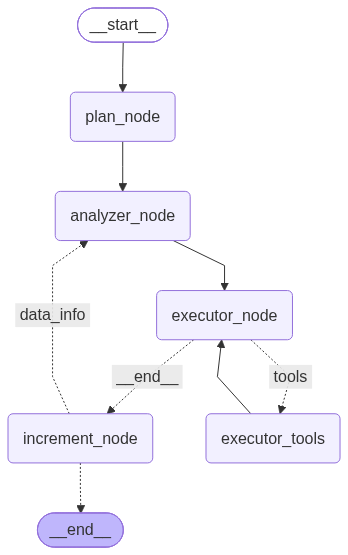

In [15]:
graph

In [16]:
# initial_state = {
#     'user_request':'generate a bar chart ',
#     'file_path':'student.csv'
# }

# output=graph.invoke(initial_state)
# print(output.content)